# Activity 5.1: Clustering

#### Objective:

This activity aims to perform classification  of unlabeled data using K Means and Agglomerative Clustering

#### Intended Learning Outcomes (ILOs):
* Build the model using K Means and Agglomerative clustering.
* Determine the optimum number of clusters using elbow method.
* Visualize the dendogram produced by the agglomerative clustering


#### Resources:
* Jupyter Notebook
* Wholesale customers data.csv

#### Procedure:

We will used K-Means clustering to cluster the clients of a wholesale distributor based on their annual spending on diverse product categories, like milk, grocery, region, etc.


Import the needed libraries

In [171]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from sklearn.cluster import KMeans

Load the dataset and check the first five rows

In [172]:
df=pd.read_csv("wholesale_customers_data.csv")
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


Check the descriptive statistics of the dataset

In [173]:
df.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


Since K-Means is a distance-based algorithm, the difference between the magnitudes of the data will create a problem. Let us apply featuring scaling to standardize the data.

In [174]:
# Use standard scaler to standardize the data
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
data_scaled = scaler.fit_transform(df)

# statistics of scaled data
pd.DataFrame(data_scaled).describe()

,0,1,2,3,4,5,6,7
count,4.400000e+02,4.400000e+02,4.400000e+02,440.000000,4.400000e+02,4.400000e+02,4.400000e+02,4.400000e+02
mean,1.614870e-17,3.552714e-16,-3.431598e-17,0.000000,-4.037175e-17,3.633457e-17,2.422305e-17,-8.074349e-18
std,1.001138e+00,1.001138e+00,1.001138e+00,1.001138,1.001138e+00,1.001138e+00,1.001138e+00,1.001138e+00
min,-6.902971e-01,-1.995342e+00,-9.496831e-01,-0.778795,-8.373344e-01,-6.283430e-01,-6.044165e-01,-5.402644e-01
25%,-6.902971e-01,-7.023369e-01,-7.023339e-01,-0.578306,-6.108364e-01,-4.804306e-01,-5.511349e-01,-3.964005e-01
50%,-6.902971e-01,5.906683e-01,-2.767602e-01,-0.294258,-3.366684e-01,-3.188045e-01,-4.336004e-01,-1.985766e-01
75%,1.448652e+00,5.906683e-01,3.905226e-01,0.189092,2.849105e-01,9.946441e-02,2.184822e-01,1.048598e-01
max,1.448652e+00,5.906683e-01,7.927738e+00,9.183650,8.936528e+00,1.191900e+01,7.967672e+00,1.647845e+01


Build the K-Means model

In [175]:
# Create cluster of 2
kmeans = KMeans(n_clusters=2, init='k-means++', n_init=10, random_state=42)

# fit the k means algorithm on scaled data
kmeans.fit(data_scaled)

KMeans(n_clusters=2, n_init=10, random_state=42)

 Calculate the inertia to evaluate how well the formed clusters are.

In [176]:
# inertia on the fitted data
kmeans.inertia_

2599.387384912305

Interpret the result of the inertia

The inertia indicates how close and compact the clusters made by the data points when plotted in a graph. Higher inertia indicates poor clustering, which the current dataset shows.

Use the elbow curve to determine the optimum number of clusters in Python.



Text(0, 0.5, 'Inertia')

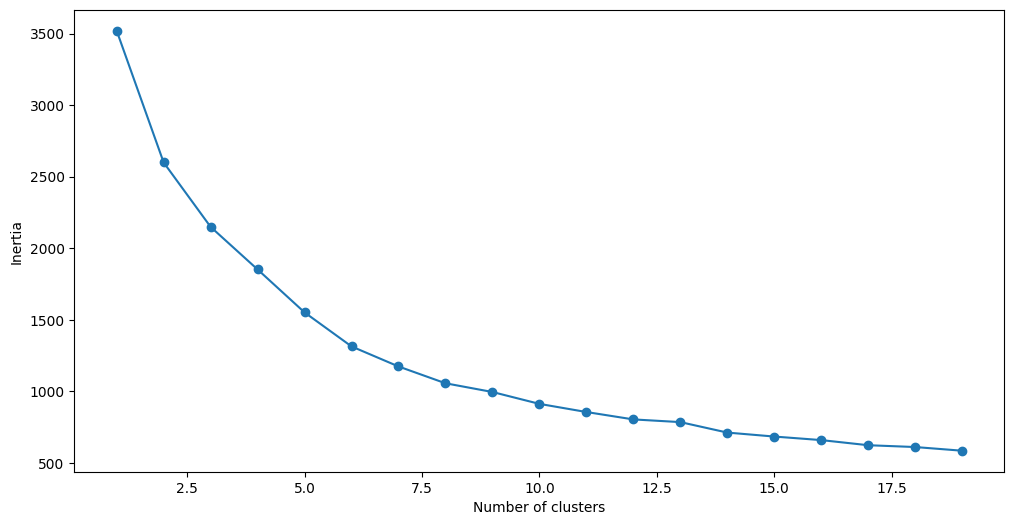

In [177]:
# fitting multiple k-means algorithms and storing the values in an empty list
SSE = []
for cluster in range(1,20):
    kmeans = KMeans(n_clusters=cluster, init='k-means++', n_init=10, random_state=42)
    kmeans.fit(data_scaled)
    SSE.append(kmeans.inertia_)

# converting the results into a dataframe and plotting them
frame = pd.DataFrame({'Cluster':range(1,20), 'SSE':SSE})
plt.figure(figsize=(12,6))
plt.plot(frame['Cluster'], frame['SSE'], marker='o')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')

Interpret the result of the elbow curve.

The elbow curve indicates how the number of clusters used in K Means affect the inertia of the clusters, and it indicated that higher clusters will return lower and better inertia.

Build a model using 5 clusters and k-means ++ initialization

In [178]:
# k means using 5 clusters and k-means++ initialization
kmeans = KMeans(n_clusters=5, init='k-means++')
kmeans.fit(data_scaled)
pred = kmeans.predict(data_scaled)

In [179]:
frame = pd.DataFrame(data_scaled)
frame['cluster'] = pred
frame['cluster'].value_counts()

,count
cluster,
0,209
1,126
3,92
2,12
4,1


There are 208 data points belonging to cluster 1 (index 1), then 125 points in cluster 2 (index 2), and so on.

Compute the centroids of the K means cluster

In [180]:
centroids = kmeans.cluster_centers_
print(centroids)

[[-6.90297086e-01  5.90668285e-01  1.02719458e-01 -3.56479221e-01
  -4.43587243e-01  7.52790095e-02 -4.43491947e-01 -9.31373298e-02]
 [ 1.44865163e+00  1.69928497e-01 -3.06362835e-01  4.17500207e-01
   6.51879518e-01 -3.57269701e-01  6.76847966e-01  6.33174701e-03]
 [ 1.27040590e+00  5.19161179e-02  1.01697969e+00  3.88384518e+00
   3.77602602e+00  2.67775570e-01  3.91009990e+00  1.07099298e+00]
 [-5.74049873e-01 -1.58776439e+00  3.22040971e-02 -3.24809935e-01
  -3.91593636e-01  2.08356115e-01 -4.23471344e-01 -1.15896320e-01]
 [-6.90297086e-01  5.90668285e-01  1.96681731e+00  5.17550306e+00
   1.28721685e+00  6.90059988e+00 -5.54861977e-01  1.64784475e+01]]


What is the purpose of the centroids?

Centroids serves as central reference point for K Means clustering, which constantly changes as the means change.

Fit an agglomerative clustering model with two clusters.

In [181]:
from sklearn.cluster import AgglomerativeClustering

ag = AgglomerativeClustering(n_clusters=2, linkage='ward', compute_full_tree=True)
ag = ag.fit(data_scaled)
df['agglom'] = ag.fit_predict(data_scaled)

Visualize the dendrogram produced by agglomerative clustering

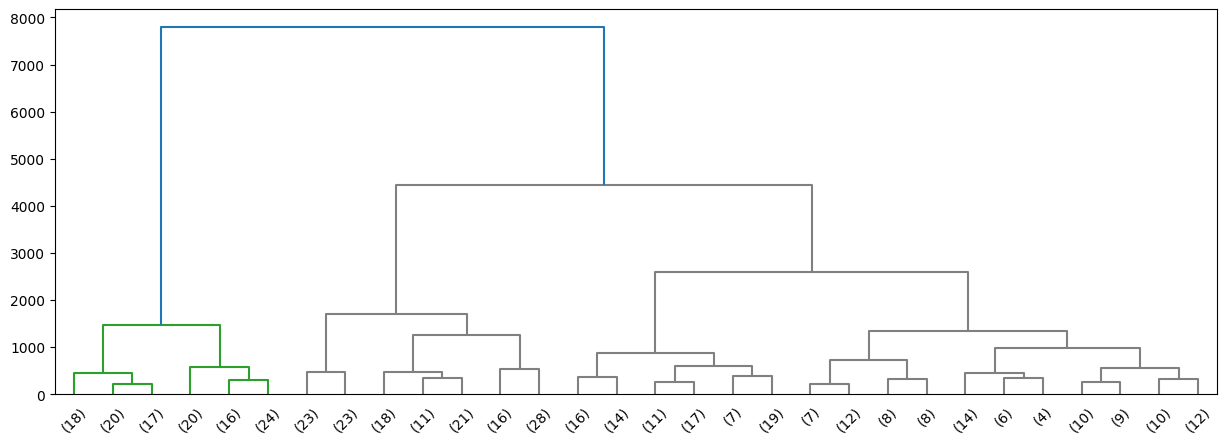

In [182]:
from scipy.cluster import hierarchy
from matplotlib import colors
import seaborn as sns

Z = hierarchy.linkage(ag.children_, method='ward')

fig, ax = plt.subplots(figsize=(15,5))

# Some color customization
dark_palette = sns.color_palette()
red = colors.to_hex(dark_palette[2])
blue = colors.to_hex(dark_palette[0])

hierarchy.set_link_color_palette([red, 'gray'])

den = hierarchy.dendrogram(Z, orientation='top',
                           p=30, truncate_mode='lastp',
                           show_leaf_counts=True, ax=ax,
                           above_threshold_color=blue)

Interpret the result of the dendogram

The dendogram indicates how the agglomorate clustering decides on the different clusters in the data points. The highlighted tree is the best among the others since it predicted the clusters efficiently.

Supplementary Activity:
* Choose your own dataset.
* Import the dataset
* Determine the number of datapoints, columns and data types
* Remove unneccesary columns
* Do data cleaning such as removing empty values(NaN), replacing missing data .
* Standardize the variables.
* Perform descriptive statistics such as mean, median and mode
* Perform data visualization
* Use k-means clustering to identify the groups of the dataset.
* Use 1 to 10 clusters
* Determine the optimum number of clusters
* Use agglomerative clustering and visualize the dendogram
* Compare the results obtained by the K means and agglomerative clustering.

#Dataset: ([What Makes a Song Go Viral ](https://www.kaggle.com/datasets/vedauv/what-makes-a-song-go-viral-10000-tracks/data))

Import dataset

In [183]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("vedauv/what-makes-a-song-go-viral-10000-tracks")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'what-makes-a-song-go-viral-10000-tracks' dataset.
Path to dataset files: /kaggle/input/what-makes-a-song-go-viral-10000-tracks


In [184]:
df_path = "/kaggle/input/what-makes-a-song-go-viral-10000-tracks/viral_songs.csv"

df = pd.read_csv(df_path)
df.head()

,track_id,track_name,artist,genre,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,streams,viral
0,track_00001,Track_00001,Artist_1519,Pop,2013,237,0.760,0.703,0.747,140.8,0.115,0.103,0.206,0.272,-9.41,661412,1
1,track_00002,Track_00002,Artist_0458,Electronic,2018,239,0.436,0.934,0.672,105.1,0.016,0.002,0.024,0.000,-9.89,1114175,1
2,track_00003,Track_00003,Artist_1386,Hip-Hop,2014,148,0.642,0.725,0.460,90.6,0.010,0.520,0.079,0.053,-5.53,105832,1
3,track_00004,Track_00004,Artist_0865,Classical,2012,216,0.326,0.456,0.299,71.3,0.966,0.042,0.000,0.074,-11.39,915397,0
4,track_00005,Track_00005,Artist_0192,Pop,2011,277,0.599,0.683,0.700,132.6,0.078,0.113,0.000,0.036,-5.56,3690733,1


Preprocessing

In [185]:
df.shape

(10000, 17)

In [186]:
df.columns

Index(['track_id', 'track_name', 'artist', 'genre', 'release_year',
       'duration_sec', 'danceability', 'energy', 'valence', 'tempo_bpm',
       'acousticness', 'instrumentalness', 'speechiness', 'liveness',
       'loudness_db', 'streams', 'viral'],
      dtype='object')

In [187]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   track_id          10000 non-null  object 
 1   track_name        10000 non-null  object 
 2   artist            10000 non-null  object 
 3   genre             10000 non-null  object 
 4   release_year      10000 non-null  int64  
 5   duration_sec      10000 non-null  int64  
 6   danceability      10000 non-null  float64
 7   energy            10000 non-null  float64
 8   valence           10000 non-null  float64
 9   tempo_bpm         10000 non-null  float64
 10  acousticness      10000 non-null  float64
 11  instrumentalness  10000 non-null  float64
 12  speechiness       10000 non-null  float64
 13  liveness          10000 non-null  float64
 14  loudness_db       10000 non-null  float64
 15  streams           10000 non-null  int64  
 16  viral             10000 non-null  int64  

In [188]:
df.describe()

,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,streams,viral
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,1.000000e+04,10000.00000
mean,2017.499400,208.776800,0.611709,0.651938,0.582280,110.975940,0.295583,0.177337,0.087453,0.184925,-7.975896,2.415685e+06,0.36050
std,4.607854,49.967024,0.192612,0.187686,0.177984,19.017206,0.263574,0.161221,0.069674,0.114307,2.976277,9.721026e+06,0.48017
min,2010.000000,60.000000,0.000000,0.005000,0.000000,50.000000,0.000000,0.000000,0.000000,0.000000,-18.740000,1.340000e+02,0.00000
25%,2013.000000,175.000000,0.482000,0.529000,0.459000,98.000000,0.085000,0.017000,0.027000,0.099000,-9.980000,8.671450e+04,0.00000
50%,2018.000000,209.000000,0.624000,0.669000,0.582000,111.300000,0.235000,0.154000,0.080000,0.180000,-7.980000,3.290580e+05,0.00000
75%,2022.000000,242.000000,0.753000,0.787000,0.703000,124.500000,0.441000,0.288000,0.134000,0.264000,-5.990000,1.343092e+06,1.00000
max,2025.000000,433.000000,1.000000,1.000000,1.000000,177.800000,1.000000,0.934000,0.381000,0.623000,0.000000,4.430683e+08,1.00000


In [189]:
df.isna().sum()

,0
track_id,0
track_name,0
artist,0
genre,0
release_year,0
duration_sec,0
danceability,0
energy,0
valence,0
tempo_bpm,0


In [190]:
df.duplicated().sum()

np.int64(0)

In [191]:
numeric_df = df.select_dtypes(include='number')
numeric_df = numeric_df.drop(columns=["release_year"])
numeric_df.head()

,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,streams,viral
0,237,0.760,0.703,0.747,140.8,0.115,0.103,0.206,0.272,-9.41,661412,1
1,239,0.436,0.934,0.672,105.1,0.016,0.002,0.024,0.000,-9.89,1114175,1
2,148,0.642,0.725,0.460,90.6,0.010,0.520,0.079,0.053,-5.53,105832,1
3,216,0.326,0.456,0.299,71.3,0.966,0.042,0.000,0.074,-11.39,915397,0
4,277,0.599,0.683,0.700,132.6,0.078,0.113,0.000,0.036,-5.56,3690733,1


In [192]:
numeric_df.mean()

,0
duration_sec,2.087768e+02
danceability,6.117090e-01
energy,6.519382e-01
valence,5.822803e-01
tempo_bpm,1.109759e+02
acousticness,2.955829e-01
instrumentalness,1.773374e-01
speechiness,8.745300e-02
liveness,1.849249e-01
loudness_db,-7.975896e+00


In [193]:
numeric_df.median()

,0
duration_sec,209.000
danceability,0.624
energy,0.669
valence,0.582
tempo_bpm,111.300
acousticness,0.235
instrumentalness,0.154
speechiness,0.080
liveness,0.180
loudness_db,-7.980


In [194]:
numeric_df.mode()

,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,streams,viral
0,220,1.0,1.0,1.0,114.5,0.0,0.0,0.0,0.0,0.0,37774,0


Standardize

In [195]:
# Feature Engineering
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
df_scaled = scaler.fit_transform(numeric_df)

In [196]:
df_copy = pd.DataFrame(numeric_df)

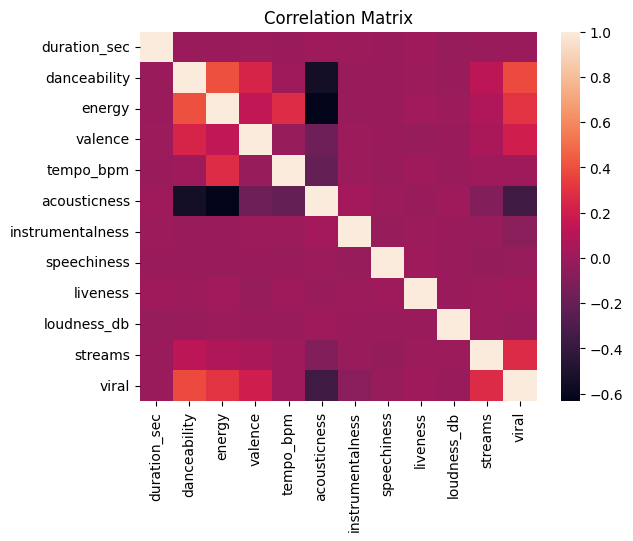

In [197]:
# Correlation matrix
corr = df_copy.corr()
sns.heatmap(corr)

plt.title("Correlation Matrix")

plt.show()

EDA

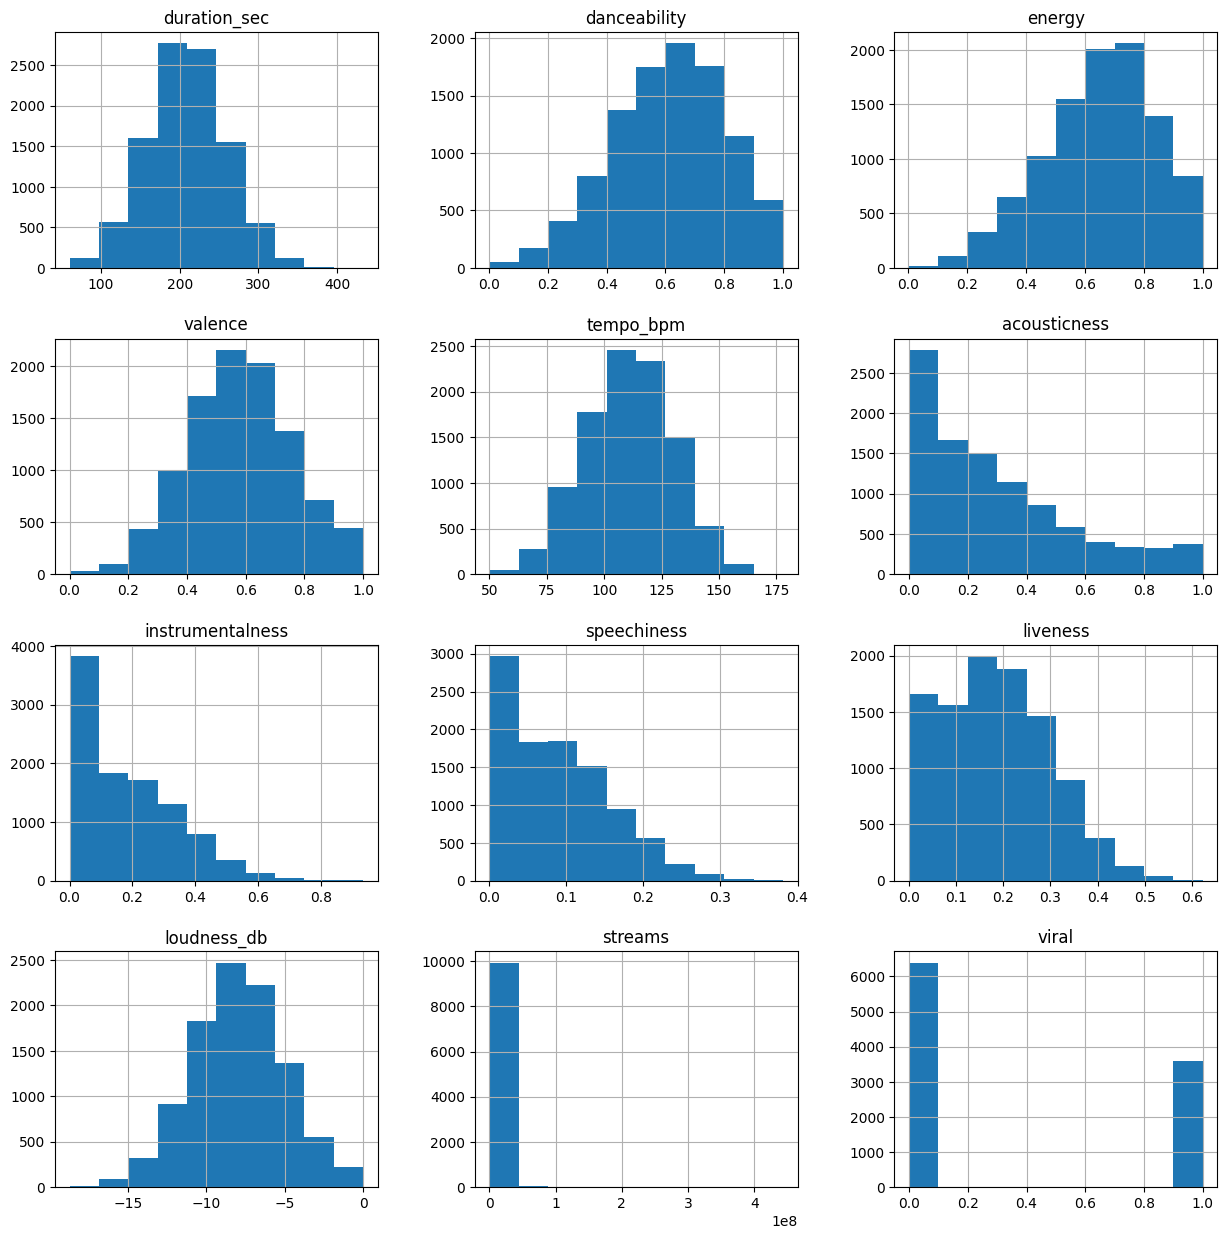

In [198]:
# Distribution of each feature
numeric_df.hist(figsize=(15,15))
plt.show()

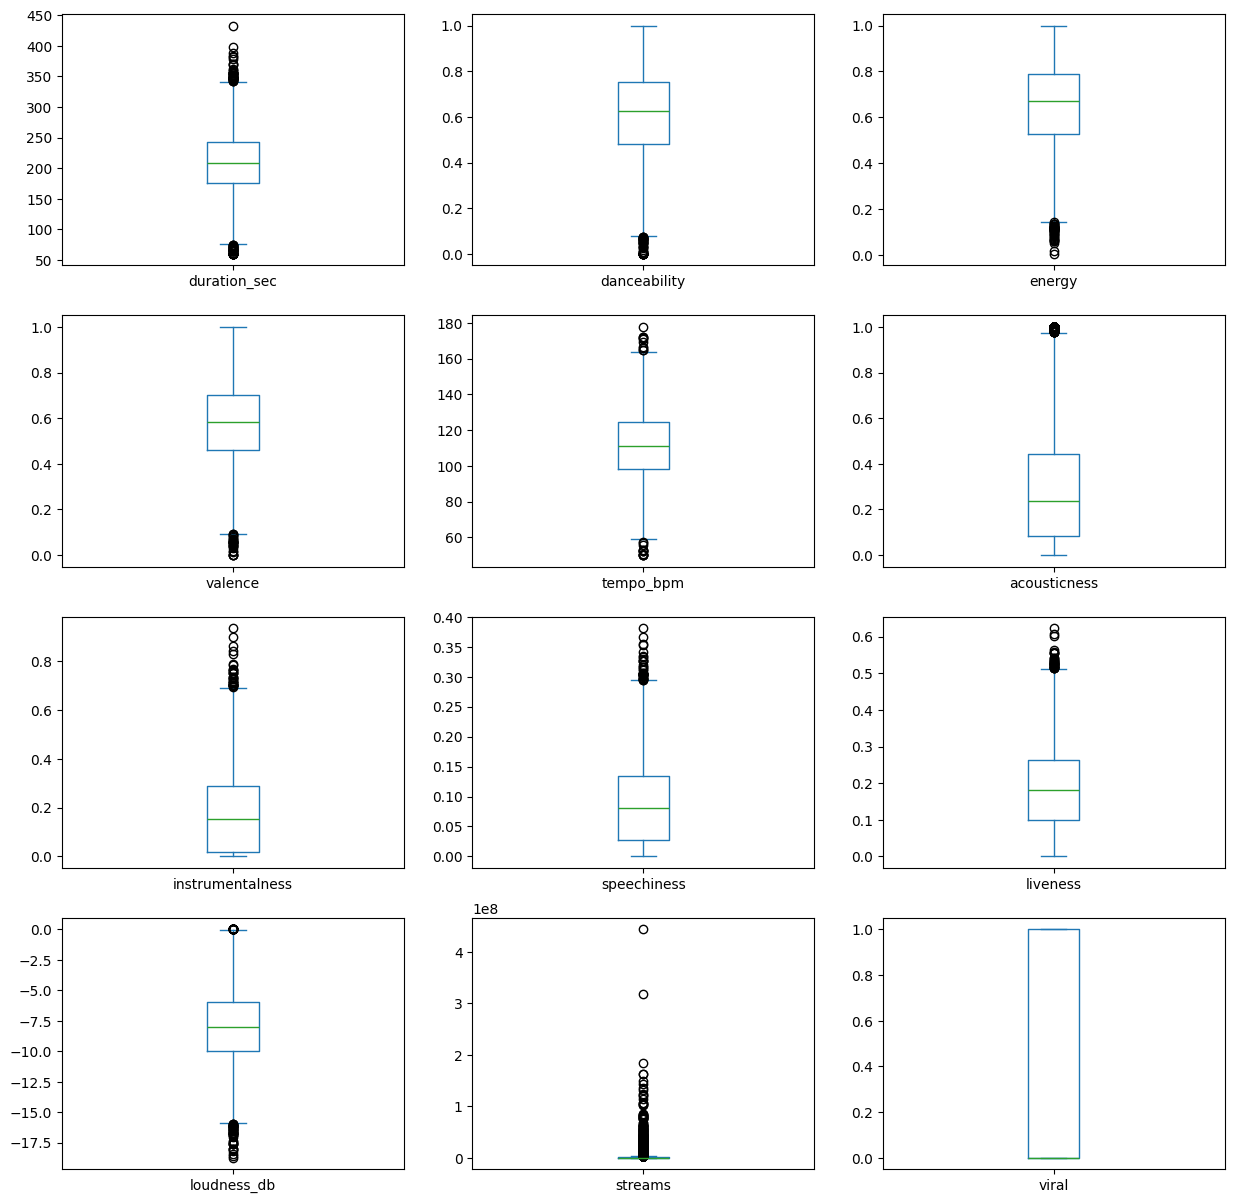

In [199]:
# box plot
numeric_df.plot(kind='box', subplots=True, layout=(4,3), figsize=(15,15))
plt.show()

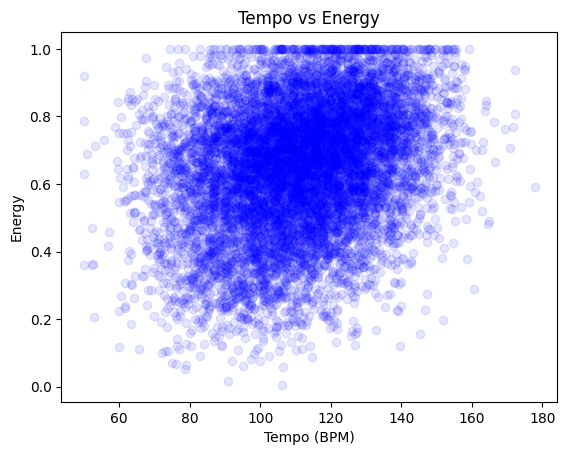

In [200]:
# Tempo vs Liveness
plt.scatter(df['tempo_bpm'], df['energy'], alpha=0.1, color="blue")
plt.xlabel('Tempo (BPM)')
plt.ylabel('Energy')
plt.title('Tempo vs Energy')
plt.show()

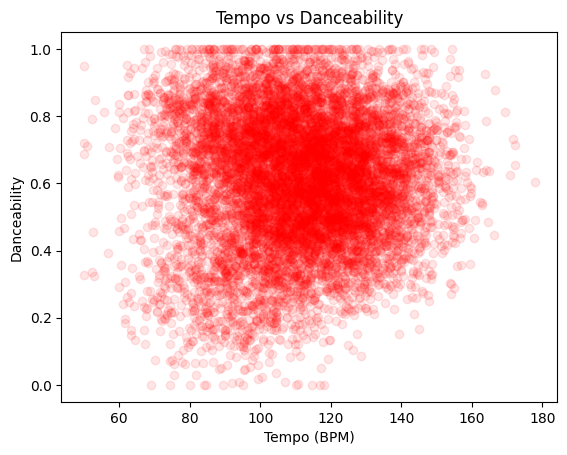

In [201]:
# Tempo vs Danceability
plt.scatter(df['tempo_bpm'], df['danceability'], alpha=0.1, color="red")
plt.xlabel('Tempo (BPM)')
plt.ylabel('Danceability')
plt.title('Tempo vs Danceability')
plt.show()

Model Training

- Use k-means clustering to identify the groups of the dataset.
- Use 1 to 10 clusters
- Determine the optimum number of clusters
- Use agglomerative clustering and visualize the dendogram
- Compare the results obtained by the K means and agglomerative clustering.

K-Means testing

In [208]:
# KMeans (5 clusters)
kmeans = KMeans(n_clusters=5, init='k-means++', n_init=10, random_state=42)

# Fit
kmeans.fit(data_scaled)

KMeans(n_clusters=5, n_init=10, random_state=42)

In [210]:
# inertia on the fitted data
kmeans.inertia_

# inertia too high

85131.0635718932

Try multiple cluster values

Text(0, 0.5, 'Inertia')

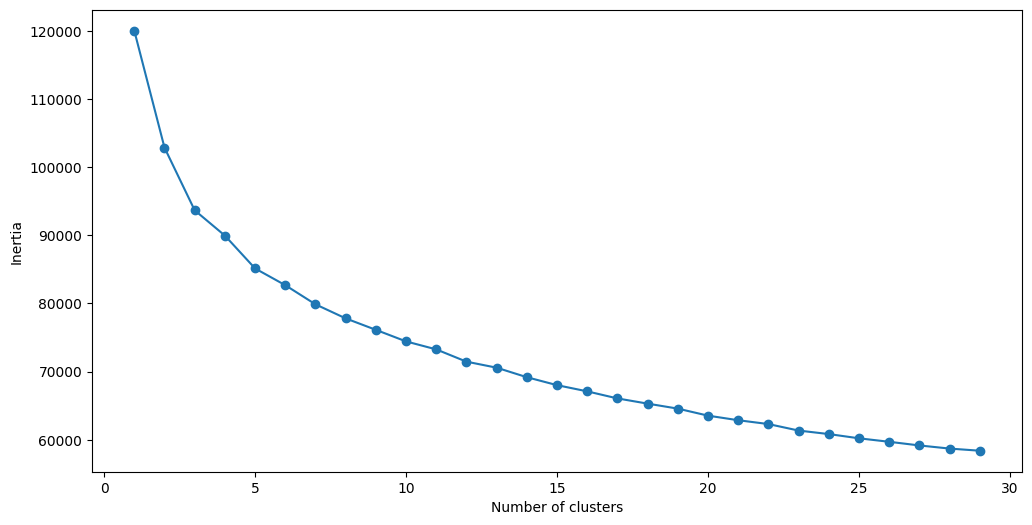

In [213]:
SSE = []
for cluster in range(1,30):
    kmeans = KMeans(n_clusters=cluster, init='k-means++', n_init=10, random_state=42)
    kmeans.fit(data_scaled)
    SSE.append(kmeans.inertia_)

frame = pd.DataFrame({'Cluster':range(1,30), 'SSE':SSE})
plt.figure(figsize=(12,6))
plt.plot(frame['Cluster'], frame['SSE'], marker='o')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')

Build a model using 5 clusters and k-means ++ initialization

In [220]:
# k means using 5 clusters and k-means++ initialization
kmeans = KMeans(n_clusters=25, init='k-means++')
kmeans.fit(data_scaled)
pred = kmeans.predict(data_scaled)

In [221]:
frame = pd.DataFrame(data_scaled)
frame['cluster'] = pred
frame['cluster'].value_counts()

,count
cluster,
9,555
16,542
5,525
1,518
19,499
20,496
14,487
21,482
3,478


Optimum number: 9

Compute the centroids of the K means cluster

In [222]:
centroids = kmeans.cluster_centers_
print(centroids)

[[-5.96216745e-01 -6.35557582e-01 -8.61003738e-01 -2.46715860e-01
   2.06759533e-01  8.62014048e-01  1.52989804e+00 -4.52336191e-02
   2.97220626e-02 -5.27239665e-02 -1.88794942e-01 -6.91768327e-01]
 [ 9.01860623e-01  7.09051407e-01  2.77658803e-01  2.89148011e-01
  -7.69118162e-01 -5.33113264e-01 -3.97586424e-01 -4.92129742e-01
  -5.58710145e-01  2.70194601e-02  1.29492252e-01  1.32384648e+00]
 [-4.91599073e-01  3.99454780e-01  2.06506971e-02  5.05550184e-01
  -2.48213746e-01 -2.21346925e-01 -1.69519502e-01  1.49356852e+00
  -2.66503928e-01  7.62485216e-03 -1.96632764e-01 -7.50813997e-01]
 [-2.00531833e-01  6.89054078e-01  4.20909429e-01  3.46295598e-01
  -1.60102990e-01 -4.72398115e-01  1.49473169e+00 -1.88860437e-01
  -4.86328688e-02  2.39972911e-02  1.35504123e-01  1.33188780e+00]
 [-5.99445175e-01 -4.94032895e-01 -8.53461494e-01 -3.52247114e-01
   1.62858736e-01  7.93288249e-01 -5.47621186e-01 -4.16295189e-01
  -8.34676622e-01 -1.48015336e-01 -1.87338642e-01 -6.92587925e-01]
 [ 4.

Fit Agglomerative clustering model

In [225]:
from sklearn.cluster import AgglomerativeClustering

ag = AgglomerativeClustering(n_clusters=25, linkage='ward', compute_full_tree=True)
ag = ag.fit(data_scaled)
df['agglom'] = ag.fit_predict(data_scaled)

Visualize dendrogram

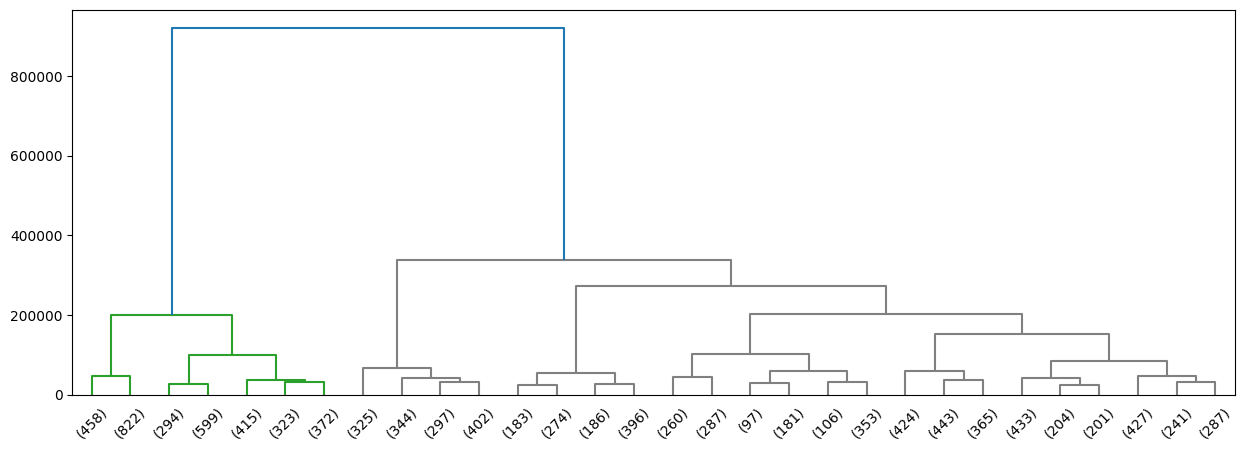

In [224]:
from scipy.cluster import hierarchy
from matplotlib import colors
import seaborn as sns

Z = hierarchy.linkage(ag.children_, method='ward')

fig, ax = plt.subplots(figsize=(15,5))

dark_palette = sns.color_palette()
red = colors.to_hex(dark_palette[2])
blue = colors.to_hex(dark_palette[0])

hierarchy.set_link_color_palette([red, 'gray'])

den = hierarchy.dendrogram(Z, orientation='top',
                           p=30, truncate_mode='lastp',
                           show_leaf_counts=True, ax=ax,
                           above_threshold_color=blue)

In [226]:
# Compare performances of models using silhouette scores
from sklearn.metrics import silhouette_score

# Calculate silhouette scores (using a sample of 5000 if dataset is large, or full dataset)
print("Calculating silhouette scores (this might take a few moments)... ")

# K-Means Silhouette Score
kmeans_silhouette = silhouette_score(data_scaled, pred, metric='euclidean', random_state=42)

# Agglomerative Silhouette Score
ag_labels = df['agglom']
agglom_silhouette = silhouette_score(data_scaled, ag_labels, metric='euclidean')

print(f"\nK-Means Clustering Silhouette Score (25 clusters): {kmeans_silhouette:.4f}")
print(f"Agglomerative Hierarchical Clustering Silhouette Score (25 clusters): {agglom_silhouette:.4f}")

# Summary analysis
if kmeans_silhouette > agglom_silhouette:
    print("\nSummary: K-Means has a higher Silhouette Score, indicating more compact and well-separated clusters on average.")
elif agglom_silhouette > kmeans_silhouette:
    print("\nSummary: Agglomerative Clustering has a higher Silhouette Score, indicating better-defined cluster boundaries for this hierarchical layout.")
else:
    print("\nSummary: Both models performed equally in terms of silhouette-based compactness and separation.")

Calculating silhouette scores (this might take a few moments)... 

K-Means Clustering Silhouette Score (25 clusters): 0.0760
Agglomerative Hierarchical Clustering Silhouette Score (25 clusters): 0.0202

Summary: K-Means has a higher Silhouette Score, indicating more compact and well-separated clusters on average.


#### Conclusion

The activity mainly tackles on 2 clustering unsupervised learning models, namely K-Means and Agglomeration Clustering. In accomplishing the activity, we analyzed the Wholesale Customers Dataset in the procedure part. Before applying these models, a series of preprocessing, cleaning, and exploratory data analysis (EDA) is needed to explore the data more and know the highlights of the data points. After this, we built K-Means clustering models and mapped the Sum of Squared Errors (SSE) over several cluster counts using the Elbow Method to identify the optimal cluster groupings. We then constructed an Agglomerative Hierarchical Clustering model and visualized the dataset's structural groupings using a dendrogram. After model training, we compared their results and defined their performances. These procedure were also made in the supplementary activity, which tackled on What Makes a Song Go Viral dataset, and it showed that the K Means clustering model performed better in it. In conclusion, the use of these clustering models are based on the applied dataset, since each model provides different performances and applications